<a href="https://colab.research.google.com/github/Abdoulaye279/Machine-Learning-and-AI-for-Physics/blob/main/Energy_Calibration_and_BetaCosmic_Separation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Energy calibration:**

A scintillation detector measures gamma lines of known energy (calibration.csv). For each peak we
record its position in the ADC (adc_channel) and the detector temperature (temperature_C). We want
to predict the energy energy_keV from these two measurements.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Given parameters
FILE            = "calibration.csv"
FEATURES        = ["adc_channel", "temperature_C"]
TARGET          = "energy_keV"
T_MIN, T_MAX    = 0, 50
TEST_SIZE       = 0.2
ETAS            = [0.01, 0.1]
N_EPOCHS        = 500

### Part A: Data



In [ ]:
df = pd.read_csv(FILE)
print("shape:", df.shape)
display(df.head())
print("missing values per column:")
print(df.isna().sum())
print("duplicated rows:", df.duplicated().sum())

clean = df.drop_duplicates().dropna()
clean = clean[(clean["adc_channel"] > 0) & (clean["temperature_C"] >= T_MIN) & (clean["temperature_C"] <= T_MAX)]
print("rows left:", len(clean))

shape: (203, 4)


,peak_id,adc_channel,temperature_C,energy_keV
0,P001,67.6,28.6,59.5
1,P002,1603.9,25.5,1274.5
2,P003,1455.8,19.0,1173.2
3,P004,645.7,29.5,511.0
4,P005,649.9,26.7,511.0


missing values per column:
peak_id          0
adc_channel      3
temperature_C    2
energy_keV       0
dtype: int64
duplicated rows: 3
rows left: 192


Plot `energy_keV` against `adc_channel`.

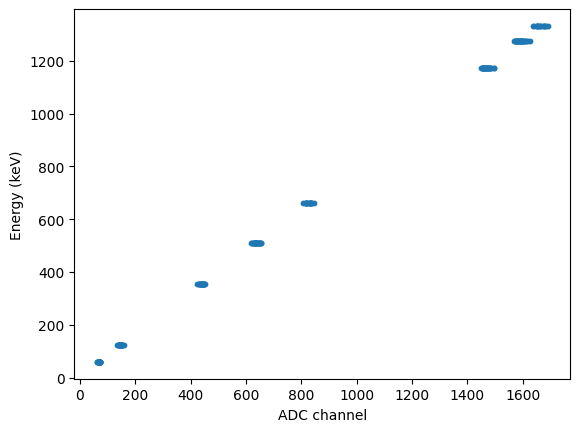

training rows: 153   test rows: 39


In [ ]:
from sklearn.model_selection import train_test_split

plt.scatter(clean["adc_channel"], clean["energy_keV"], s=10)
plt.xlabel("ADC channel")
plt.ylabel("Energy (keV)")
plt.show()

train, test = train_test_split(clean, test_size=TEST_SIZE, random_state=42)
print("training rows:", len(train), "  test rows:", len(test))

### Part B: Linear regression



In [ ]:
X1 = np.column_stack([np.ones(len(train)), train["adc_channel"]])
theta = np.linalg.lstsq(X1, train[TARGET])[0]
print("theta0 =", theta[0], "keV")
print("theta1 =", theta[1], "keV/channel")

theta0 = 4.73655119381394 keV
theta1 = 0.7965143895845064 keV/channel


In [ ]:
from sklearn.linear_model import LinearRegression

simple = LinearRegression()
simple.fit(train[["adc_channel"]], train[TARGET])

multi = LinearRegression()
multi.fit(train[["adc_channel", "temperature_C"]], train[TARGET])

print("simple : theta0 =", simple.intercept_, " theta1 =", simple.coef_[0])
print("with T : theta0 =", multi.intercept_, " theta1 =", multi.coef_[0], " theta2 =", multi.coef_[1])

simple : theta0 = 4.736551193813511  theta1 = 0.7965143895845069
with T : theta0 = 34.12244286062128  theta1 = 0.7963128110939731  theta2 = -1.3200068743529303


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_simple = simple.predict(test[["adc_channel"]])
pred_multi = multi.predict(test[["adc_channel", "temperature_C"]])

print("simple : MAE =", mean_absolute_error(test[TARGET], pred_simple))
print("simple : RMSE =", np.sqrt(mean_squared_error(test[TARGET], pred_simple)))
print("simple : R2 =", r2_score(test[TARGET], pred_simple))
print("with T : MAE =", mean_absolute_error(test[TARGET], pred_multi))
print("with T : RMSE =", np.sqrt(mean_squared_error(test[TARGET], pred_multi)))
print("with T : R2 =", r2_score(test[TARGET], pred_multi))

simple : MAE = 4.755596057465077
simple : RMSE = 6.5671222494958785
simple : R2 = 0.9998272863725811
with T : MAE = 4.3165129336899515
with T : RMSE = 5.629776159899046
with T : R2 = 0.9998730716428489


### Part C: Gradient descent



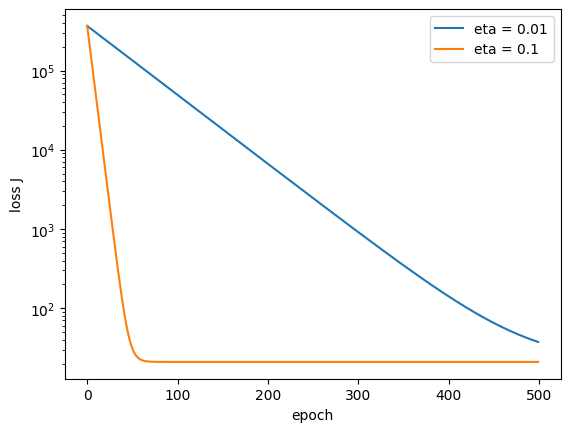

gradient descent : theta0 = 34.122442860620936  theta1 = 0.7963128110939729  theta2 = -1.3200068743529318
LinearRegression : theta0 = 34.12244286062128  theta1 = 0.7963128110939731  theta2 = -1.3200068743529303


In [ ]:
mean = train[FEATURES].mean()
std = train[FEATURES].std()
X = (train[FEATURES] - mean) / std
X = np.column_stack([np.ones(len(X)), X])
y = train[TARGET].values
N = len(y)

for eta in ETAS:
    theta = np.zeros(3)
    losses = []
    for epoch in range(N_EPOCHS):
        error = X @ theta - y
        losses.append(np.mean(error ** 2) / 2)
        theta = theta - eta / N * X.T @ error
    plt.plot(losses, label="eta = " + str(eta))
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("loss J")
plt.legend()
plt.show()

theta1 = theta[1] / std["adc_channel"]
theta2 = theta[2] / std["temperature_C"]
theta0 = theta[0] - theta1 * mean["adc_channel"] - theta2 * mean["temperature_C"]
print("gradient descent : theta0 =", theta0, " theta1 =", theta1, " theta2 =", theta2)
print("LinearRegression : theta0 =", multi.intercept_, " theta1 =", multi.coef_[0], " theta2 =", multi.coef_[1])

**Beta or cosmic?**

A Sr-90 source is placed on the axis of a detector, facing it (beta_cosmic.csv). The detector sees electrons
from the beta source and also electrons coming from cosmic rays. For each electron we know its energy
energy_MeV and cosθ (cos_theta), where θ is the angle between its track and the detector axis. The label
is label_beta: 1 for a beta and 0 for a cosmic. Our goal is to separate the two.

In [ ]:
# Given parameters
from sklearn.model_selection import StratifiedKFold

FILE            = "beta_cosmic.csv"
FEATURES        = ["energy_MeV", "cos_theta"]
TARGET          = "label_beta"
TEST_SIZE       = 0.25
E_CUT, COS_CUT  = 2.3, 0.75
K_VALUES        = [1, 3, 5, 11, 21, 51]
DEPTHS          = [1, 2, 3, 5, 10, None]
DEPTH_LABELS    = ["1", "2", "3", "5", "10", "None"]
N_TREES         = 100
N_EPOCHS_NN     = 100
BATCH_SIZE      = 32
N_VALUES        = [1, 2, 3, 4, 8, 32]
SEEDS           = [0, 1, 2, 3, 4]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Part A: Data



In [ ]:
df = pd.read_csv(FILE)
print("shape:", df.shape)
print(df.isna().sum())
print("duplicated rows:", df.duplicated().sum())

clean = df.drop_duplicates().dropna()
clean = clean[(clean["energy_MeV"] > 0) & (clean["cos_theta"] >= -1) & (clean["cos_theta"] <= 1)]
print(clean[TARGET].value_counts())

shape: (1203, 4)
event_id      0
energy_MeV    4
cos_theta     3
label_beta    0
dtype: int64
duplicated rows: 3
label_beta
1    605
0    583
Name: count, dtype: int64


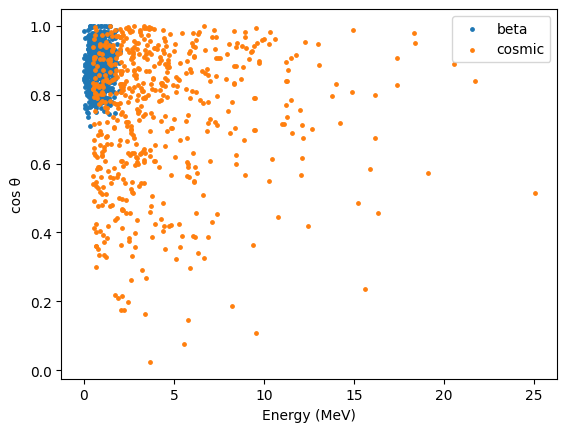

training: 891   test: 297


In [ ]:
beta = clean[clean[TARGET] == 1]
cosmic = clean[clean[TARGET] == 0]

plt.scatter(beta["energy_MeV"], beta["cos_theta"], s=6, label="beta")
plt.scatter(cosmic["energy_MeV"], cosmic["cos_theta"], s=6, label="cosmic")
plt.xlabel("Energy (MeV)")
plt.ylabel("cos θ")
plt.legend()
plt.show()

train, test = train_test_split(clean, test_size=TEST_SIZE, stratify=clean[TARGET], random_state=42)
Xtr = train[FEATURES]
ytr = train[TARGET]
Xte = test[FEATURES]
yte = test[TARGET]
print("training:", len(train), "  test:", len(test))

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

cut_pred = ((Xte["energy_MeV"] < E_CUT) & (Xte["cos_theta"] > COS_CUT))
print("simple cut accuracy:", accuracy_score(yte, cut_pred))
confusion_matrix(yte, cut_pred)

simple cut accuracy: 0.9090909090909091


array([[120,  26],
       [  1, 150]])

### Part B: Classical models


k = 1  CV accuracy = 0.865
k = 3  CV accuracy = 0.881
k = 5  CV accuracy = 0.892
k = 11  CV accuracy = 0.903
k = 21  CV accuracy = 0.911
k = 51  CV accuracy = 0.902


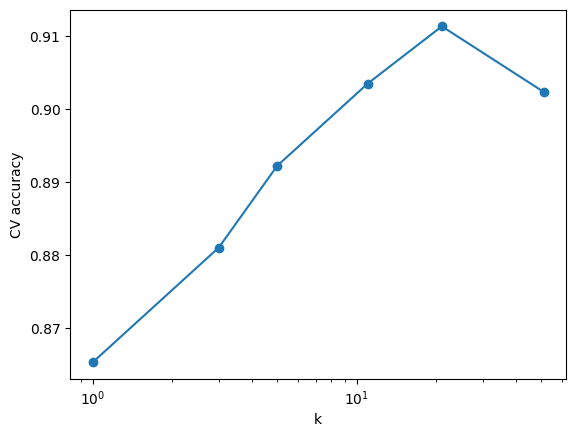

best k: 21


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

mean = Xtr.mean()
std = Xtr.std()
Xtr_s = (Xtr - mean) / std
Xte_s = (Xte - mean) / std

knn_scores = []
for k in K_VALUES:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, Xtr_s, ytr, cv=cv).mean()
    knn_scores.append(score)
    print("k =", k, " CV accuracy =", round(score, 3))

plt.plot(K_VALUES, knn_scores, "o-")
plt.xscale("log")
plt.xlabel("k")
plt.ylabel("CV accuracy")
plt.show()

best_k = K_VALUES[np.argmax(knn_scores)]
print("best k:", best_k)

 SVM:

In [ ]:
from sklearn.svm import SVC

for kernel in ["linear", "rbf"]:
    svm = SVC(kernel=kernel)
    score = cross_val_score(svm, Xtr_s, ytr, cv=cv).mean()
    print(kernel, " CV accuracy =", round(score, 3))

linear  CV accuracy = 0.901
rbf  CV accuracy = 0.91


depth = 1  training = 0.869  CV = 0.865
depth = 2  training = 0.919  CV = 0.915
depth = 3  training = 0.92  CV = 0.908
depth = 5  training = 0.927  CV = 0.906
depth = 10  training = 0.96  CV = 0.865
depth = None  training = 1.0  CV = 0.862


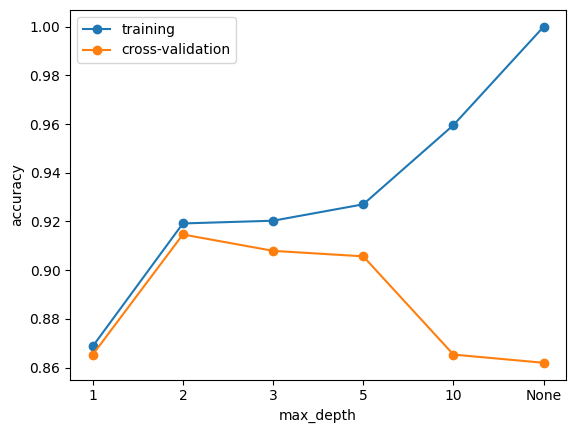

random forest CV accuracy: 0.8956060510953486


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

train_acc = []
cv_acc = []
for d in DEPTHS:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_score = cross_val_score(tree, Xtr, ytr, cv=cv).mean()
    tree.fit(Xtr, ytr)
    train_score = tree.score(Xtr, ytr)
    cv_acc.append(cv_score)
    train_acc.append(train_score)
    print("depth =", d, " training =", round(train_score, 3), " CV =", round(cv_score, 3))

plt.plot(DEPTH_LABELS, train_acc, "o-", label="training")
plt.plot(DEPTH_LABELS, cv_acc, "o-", label="cross-validation")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()

forest = RandomForestClassifier(n_estimators=N_TREES, random_state=42)
print("random forest CV accuracy:", cross_val_score(forest, Xtr, ytr, cv=cv).mean())

### Part C: Neural network



In [ ]:
from tensorflow import keras

keras.utils.set_random_seed(0)

net = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
net.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
net.fit(Xtr_s, ytr, epochs=N_EPOCHS_NN, batch_size=BATCH_SIZE, verbose=0)

print("parameters:", net.count_params())
test_loss, test_acc = net.evaluate(Xte_s, yte, verbose=0)
print("test accuracy:", test_acc)

In [ ]:
keras.utils.set_random_seed(0)
net_lin = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(8, activation="linear"),
    keras.layers.Dense(1, activation="sigmoid"),
])
net_lin.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
net_lin.fit(Xtr_s, ytr, epochs=N_EPOCHS_NN, batch_size=BATCH_SIZE, verbose=0)

svm_lin = SVC(kernel="linear")
svm_lin.fit(Xtr_s, ytr)

print("test accuracy, ReLU network  :", net.evaluate(Xte_s, yte, verbose=0)[1])
print("test accuracy, linear network:", net_lin.evaluate(Xte_s, yte, verbose=0)[1])
print("test accuracy, linear SVM    :", svm_lin.score(Xte_s, yte))

test accuracy, ReLU network  : 0.9292929172515869


test accuracy, linear network: 0.9191918969154358
test accuracy, linear SVM    : 0.9124579124579124


n = 1  validation accuracy = 0.894


n = 2  validation accuracy = 0.899


n = 3  validation accuracy = 0.899


n = 4  validation accuracy = 0.916


n = 8  validation accuracy = 0.911


n = 32  validation accuracy = 0.916


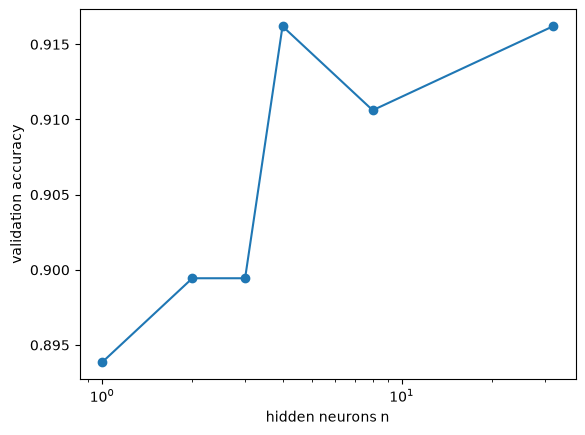

n = 2, seed = 0  validation accuracy = 0.899


n = 2, seed = 1  validation accuracy = 0.894


n = 2, seed = 2  validation accuracy = 0.475


n = 2, seed = 3  validation accuracy = 0.888


n = 2, seed = 4  validation accuracy = 0.899


In [ ]:
val_scores = []
for n in N_VALUES:
    keras.utils.set_random_seed(0)
    model = keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Dense(n, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(Xtr_s, ytr, epochs=N_EPOCHS_NN, batch_size=BATCH_SIZE, validation_split=0.2, verbose=0)
    val_acc = history.history["val_accuracy"][-1]
    val_scores.append(val_acc)
    print("n =", n, " validation accuracy =", round(val_acc, 3))

plt.plot(N_VALUES, val_scores, "o-")
plt.xscale("log")
plt.xlabel("hidden neurons n")
plt.ylabel("validation accuracy")
plt.show()

for seed in SEEDS:
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Dense(2, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(Xtr_s, ytr, epochs=N_EPOCHS_NN, batch_size=BATCH_SIZE, validation_split=0.2, verbose=0)
    print("n = 2, seed =", seed, " validation accuracy =", round(history.history["val_accuracy"][-1], 3))

### Part D: Conclusion


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

knn_final = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr_s, ytr)
svm_final = SVC(kernel="rbf").fit(Xtr_s, ytr)
tree_final = DecisionTreeClassifier(max_depth=2, random_state=42).fit(Xtr, ytr)
forest.fit(Xtr, ytr)
pred_net = (net.predict(Xte_s, verbose=0) > 0.5).astype(int).ravel()

names = ["simple cut", "kNN", "SVM rbf", "Tree", "Forest", "Network"]
preds = [cut_pred, knn_final.predict(Xte_s), svm_final.predict(Xte_s), tree_final.predict(Xte), forest.predict(Xte), pred_net]
for i in range(len(names)):
    pred = preds[i]
    print(names[i], ": accuracy", round(accuracy_score(yte, pred), 3), " precision", round(precision_score(yte, pred), 3),
          " recall", round(recall_score(yte, pred), 3), " F1", round(f1_score(yte, pred), 3))
    print(confusion_matrix(yte, pred))

simple cut : accuracy 0.909  precision 0.852  recall 0.993  F1 0.917
[[120  26]
 [  1 150]]
kNN : accuracy 0.926  precision 0.877  recall 0.993  F1 0.932
[[125  21]
 [  1 150]]
SVM rbf : accuracy 0.926  precision 0.877  recall 0.993  F1 0.932
[[125  21]
 [  1 150]]
Tree : accuracy 0.919  precision 0.876  recall 0.98  F1 0.925
[[125  21]
 [  3 148]]
Forest : accuracy 0.929  precision 0.896  recall 0.974  F1 0.933
[[129  17]
 [  4 147]]
Network : accuracy 0.929  precision 0.892  recall 0.98  F1 0.934
[[128  18]
 [  3 148]]



>
> | Model | Accuracy | Precision | Recall | F1 |
> |---|---|---|---|---|
> | simple cut | 0.909 | 0.852 | 0.993 | 0.917 |
> | kNN (k = 21) | 0.926 | 0.877 | 0.993 | 0.932 |
> | SVM rbf | 0.926 | 0.877 | 0.993 | 0.932 |
> | Tree (depth 2) | 0.919 | 0.876 | 0.980 | 0.925 |
> | Forest | 0.929 | 0.896 | 0.974 | 0.933 |
> | Network | 0.929 | 0.892 | 0.980 | 0.934 |
>
> All models reach **0.92–0.93**, against **0.909** for the simple cut. Recall is very high (almost every beta is found), precision is lower (about 17–21 of the 146 test cosmics are taken as betas).
>
> The most frequent error is a **cosmic classified as a beta**. These cosmics have the same energy and the same direction as betas: in the (E, cos θ) plane they sit inside the beta region. With only these two inputs no model can tell them apart, so 100 % is impossible; a third measurement (for example a veto detector) would be needed.